In [2]:
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download(
    "williamscott701/memotion-dataset-7k"
)

print("Dataset downloaded to:", path)

100%|██████████| 695M/695M [00:33<00:00, 21.9MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1


In [3]:
import os

print("Dataset location:", path)

for root, dirs, files in os.walk(path):
    print("\nFolder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:10])

Dataset location: /root/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1

Folder: /root/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1
Number of files: 0
Sample files: []

Folder: /root/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1/memotion_dataset_7k
Number of files: 6
Sample files: ['labels.csv', 'labels_pd_pickle', 'labels.xlsx', 'reference.csv', 'reference.xlsx', 'reference_df_pickle']

Folder: /root/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1/memotion_dataset_7k/images
Number of files: 6992
Sample files: ['image_6312.jpg', 'image_1466.jpg', 'image_3543.jpg', 'image_4158.jpg', 'image_534.JPG', 'image_4389.jpg', 'image_1308.jpg', 'image_3496.png', 'image_4349.jpeg', 'image_3396.jpg']


In [4]:
import pandas as pd
import os

dataset_folder = os.path.join(path, "memotion_dataset_7k")

labels = pd.read_csv(
    os.path.join(dataset_folder, "labels.csv")
)

print("Dataset shape:", labels.shape)

print("\nColumn names:")
print(labels.columns.tolist())

print("\nFirst 5 rows:")
display(labels.head())

print("\nMissing values:")
print(labels.isnull().sum())

Dataset shape: (6992, 9)

Column names:
['Unnamed: 0', 'image_name', 'text_ocr', 'text_corrected', 'humour', 'sarcasm', 'offensive', 'motivational', 'overall_sentiment']

First 5 rows:


,Unnamed: 0,image_name,text_ocr,text_corrected,humour,sarcasm,offensive,motivational,overall_sentiment
0,0,image_1.jpg,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,hilarious,general,not_offensive,not_motivational,very_positive
1,1,image_2.jpeg,The best of #10 YearChallenge! Completed in le...,The best of #10 YearChallenge! Completed in le...,not_funny,general,not_offensive,motivational,very_positive
2,2,image_3.JPG,Sam Thorne @Strippin ( Follow Follow Saw every...,Sam Thorne @Strippin ( Follow Follow Saw every...,very_funny,not_sarcastic,not_offensive,not_motivational,positive
3,3,image_4.png,10 Year Challenge - Sweet Dee Edition,10 Year Challenge - Sweet Dee Edition,very_funny,twisted_meaning,very_offensive,motivational,positive
4,4,image_5.png,10 YEAR CHALLENGE WITH NO FILTER 47 Hilarious ...,10 YEAR CHALLENGE WITH NO FILTER 47 Hilarious ...,hilarious,very_twisted,very_offensive,not_motivational,neutral



Missing values:
Unnamed: 0             0
image_name             0
text_ocr             161
text_corrected         5
humour                 0
sarcasm                0
offensive              0
motivational           0
overall_sentiment      0
dtype: int64


Total labelled memes: 6992

Original sentiment distribution:
overall_sentiment
positive         3127
neutral          2201
very_positive    1033
negative          480
very_negative     151
Name: count, dtype: int64


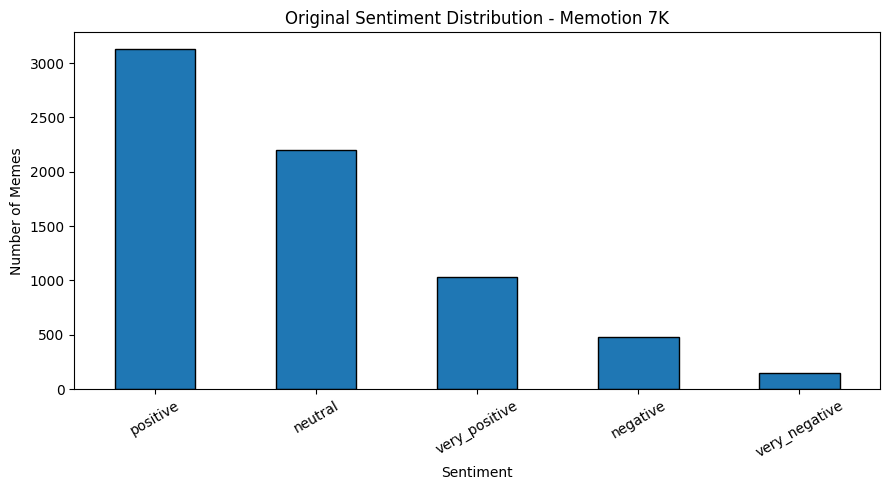

In [5]:
import matplotlib.pyplot as plt

print("Total labelled memes:", len(labels))

print("\nOriginal sentiment distribution:")
print(labels["overall_sentiment"].value_counts(dropna=False))

plt.figure(figsize=(9, 5))

labels["overall_sentiment"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Original Sentiment Distribution - Memotion 7K")
plt.xlabel("Sentiment")
plt.ylabel("Number of Memes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [6]:
# Map original five sentiment labels into three classes

sentiment_mapping = {
    "very_positive": "positive",
    "positive": "positive",
    "neutral": "neutral",
    "negative": "negative",
    "very_negative": "negative"
}

# Create a new sentiment column
labels["sentiment_3class"] = labels["overall_sentiment"].map(
    sentiment_mapping
)

# Verify the new distribution
print("Three-class sentiment distribution:")
print(labels["sentiment_3class"].value_counts())

print("\nTotal samples:", len(labels))

print("\nUnmapped labels:")
print(labels["sentiment_3class"].isnull().sum())

Three-class sentiment distribution:
sentiment_3class
positive    4160
neutral     2201
negative     631
Name: count, dtype: int64

Total samples: 6992

Unmapped labels:
0


In [7]:
import os

# Location of meme images
image_folder = os.path.join(dataset_folder, "images")

# Create full image paths
labels["image_path"] = labels["image_name"].apply(
    lambda name: os.path.join(image_folder, name)
)

# Check image availability
labels["image_exists"] = labels["image_path"].apply(os.path.isfile)

print("Total records:", len(labels))
print("Images found:", labels["image_exists"].sum())
print("Missing images:", (~labels["image_exists"]).sum())

# Prepare text: prefer corrected text, fall back to OCR
labels["clean_text"] = (
    labels["text_corrected"]
    .fillna(labels["text_ocr"])
    .fillna("")
    .astype(str)
    .str.strip()
)

print("\nEmpty text records:",
      labels["clean_text"].eq("").sum())

print("\nExample:")
display(labels[
    ["image_name", "clean_text", "sentiment_3class", "image_exists"]
].head())

Total records: 6992
Images found: 6992
Missing images: 0

Empty text records: 4

Example:


,image_name,clean_text,sentiment_3class,image_exists
0,image_1.jpg,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,positive,True
1,image_2.jpeg,The best of #10 YearChallenge! Completed in le...,positive,True
2,image_3.JPG,Sam Thorne @Strippin ( Follow Follow Saw every...,positive,True
3,image_4.png,10 Year Challenge - Sweet Dee Edition,positive,True
4,image_5.png,10 YEAR CHALLENGE WITH NO FILTER 47 Hilarious ...,neutral,True


In [8]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels["sentiment_3class"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["sentiment_3class"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTotal samples:",
      len(train_df) + len(val_df) + len(test_df))

print("\nTraining class distribution:")
print(train_df["sentiment_3class"].value_counts())

print("\nValidation class distribution:")
print(val_df["sentiment_3class"].value_counts())

print("\nTesting class distribution:")
print(test_df["sentiment_3class"].value_counts())

Training samples: 4894
Validation samples: 1049
Testing samples: 1049

Total samples: 6992

Training class distribution:
sentiment_3class
positive    2912
neutral     1540
negative     442
Name: count, dtype: int64

Validation class distribution:
sentiment_3class
positive    624
neutral     330
negative     95
Name: count, dtype: int64

Testing class distribution:
sentiment_3class
positive    624
neutral     331
negative     94
Name: count, dtype: int64


In [9]:
import hashlib
from collections import defaultdict

# Calculate a unique fingerprint for each image
def image_hash(file_path):
    sha = hashlib.sha256()
    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)
    return sha.hexdigest()

labels["image_hash"] = labels["image_path"].apply(image_hash)

# Check exact duplicate images
duplicate_count = labels["image_hash"].duplicated().sum()

print("Total memes:", len(labels))
print("Exact duplicate images:", duplicate_count)

# Check whether duplicates cross dataset splits
train_hashes = set(labels.loc[train_df.index, "image_hash"])
val_hashes = set(labels.loc[val_df.index, "image_hash"])
test_hashes = set(labels.loc[test_df.index, "image_hash"])

print("\nDuplicate hashes between splits:")
print("Train vs Validation:", len(train_hashes & val_hashes))
print("Train vs Test:", len(train_hashes & test_hashes))
print("Validation vs Test:", len(val_hashes & test_hashes))

Total memes: 6992
Exact duplicate images: 25

Duplicate hashes between splits:
Train vs Validation: 2
Train vs Test: 6
Validation vs Test: 2


In [10]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# Use the full dataset
data = labels.copy()

# Group identical images together
groups = data["image_hash"]
y = data["sentiment_3class"]

# First split: approximately 70% train, 30% remaining
sgkf1 = StratifiedGroupKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

splits1 = list(sgkf1.split(data, y, groups))

# Select a combination of 3 folds closest to 30%
from itertools import combinations

best_combo = min(
    combinations(range(10), 3),
    key=lambda combo: abs(
        sum(len(splits1[i][1]) for i in combo) / len(data) - 0.30
    )
)

temp_idx = np.concatenate([splits1[i][1] for i in best_combo])
train_idx = np.setdiff1d(np.arange(len(data)), temp_idx)

train_df = data.iloc[train_idx].copy()
temp_df = data.iloc[temp_idx].copy()

# Second split: approximately 15% validation, 15% test
sgkf2 = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    sgkf2.split(
        temp_df,
        temp_df["sentiment_3class"],
        temp_df["image_hash"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify all records are retained
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

# Verify no identical images cross splits
train_h = set(train_df["image_hash"])
val_h = set(val_df["image_hash"])
test_h = set(test_df["image_hash"])

print("\nDuplicate hashes between splits:")
print("Train vs Validation:", len(train_h & val_h))
print("Train vs Test:", len(train_h & test_h))
print("Validation vs Test:", len(val_h & test_h))

print("\nClass distribution:")
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(df["sentiment_3class"].value_counts())

Training: 4894
Validation: 1048
Testing: 1050

Total: 6992

Duplicate hashes between splits:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

Class distribution:

Train:
sentiment_3class
positive    2916
neutral     1534
negative     444
Name: count, dtype: int64

Validation:
sentiment_3class
positive    641
neutral     316
negative     91
Name: count, dtype: int64

Test:
sentiment_3class
positive    603
neutral     351
negative     96
Name: count, dtype: int64


In [11]:
import os

# Create a folder for project outputs
output_folder = "/content/memotion_project"
os.makedirs(output_folder, exist_ok=True)

# Save the final splits
train_df.to_csv(
    os.path.join(output_folder, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(output_folder, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(output_folder, "test.csv"),
    index=False
)

print("Dataset splits saved successfully!")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nFiles saved in:", output_folder)

Dataset splits saved successfully!
Training: 4894
Validation: 1048
Testing: 1050

Files saved in: /content/memotion_project


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from sklearn.pipeline import Pipeline

# Create text-only classification pipeline
text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using the full training set
text_model.fit(
    train_df["clean_text"],
    train_df["sentiment_3class"]
)

# Predict on training and validation sets
train_predictions = text_model.predict(
    train_df["clean_text"]
)

val_predictions = text_model.predict(
    val_df["clean_text"]
)

# Evaluate performance
print("TEXT-ONLY MODEL RESULTS")

print("\nTraining Accuracy:",
      accuracy_score(
          train_df["sentiment_3class"],
          train_predictions
      ))

print("Training Macro F1:",
      f1_score(
          train_df["sentiment_3class"],
          train_predictions,
          average="macro"
      ))

print("\nValidation Accuracy:",
      accuracy_score(
          val_df["sentiment_3class"],
          val_predictions
      ))

print("Validation Macro F1:",
      f1_score(
          val_df["sentiment_3class"],
          val_predictions,
          average="macro"
      ))

print("\nValidation Classification Report:")
print(classification_report(
    val_df["sentiment_3class"],
    val_predictions,
    digits=4
))

TEXT-ONLY MODEL RESULTS

Training Accuracy: 0.8624846751123825
Training Macro F1: 0.8477559359226788

Validation Accuracy: 0.44274809160305345
Validation Macro F1: 0.3494555553208866

Validation Classification Report:
              precision    recall  f1-score   support

    negative     0.1149    0.1868    0.1423        91
     neutral     0.3242    0.3734    0.3471       316
    positive     0.6138    0.5133    0.5590       641

    accuracy                         0.4427      1048
   macro avg     0.3509    0.3578    0.3495      1048
weighted avg     0.4832    0.4427    0.4589      1048



In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

results = []
models = {}

for c_value in [0.01, 0.1, 1.0, 10.0]:

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            C=c_value,
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(
        train_df["clean_text"],
        train_df["sentiment_3class"]
    )

    train_pred = model.predict(train_df["clean_text"])
    val_pred = model.predict(val_df["clean_text"])

    results.append({
        "C": c_value,
        "Train Macro F1": f1_score(
            train_df["sentiment_3class"],
            train_pred,
            average="macro"
        ),
        "Validation Macro F1": f1_score(
            val_df["sentiment_3class"],
            val_pred,
            average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            val_df["sentiment_3class"],
            val_pred
        )
    })

    models[c_value] = model

results_df = pd.DataFrame(results)

display(results_df.round(4))

best_c = results_df.loc[
    results_df["Validation Macro F1"].idxmax(), "C"
]

best_text_model = models[best_c]

print("\nBest C:", best_c)
print(
    "Best Validation Macro F1:",
    results_df["Validation Macro F1"].max()
)

,C,Train Macro F1,Validation Macro F1,Validation Accuracy
0,0.01,0.6276,0.3338,0.3817
1,0.10,0.6861,0.3383,0.3950
2,1.00,0.8426,0.3526,0.4447
3,10.00,0.9744,0.3453,0.4656



Best C: 1.0
Best Validation Macro F1: 0.3525902619904168


In [14]:
import torch
import torchvision.models as models
from torchvision.models import ResNet50_Weights

device = torch.device("cpu")

# Load pretrained ResNet50
weights = ResNet50_Weights.DEFAULT
resnet = models.resnet50(weights=weights)

# Remove final classification layer
resnet.fc = torch.nn.Identity()

# Set model to evaluation mode
resnet = resnet.to(device)
resnet.eval()

# Image preprocessing
image_transform = weights.transforms()

print("ResNet50 loaded successfully!")
print("Device:", device)
print("Feature dimension:", 2048)

print("Training data available:", "train_df" in globals())
print("Validation data available:", "val_df" in globals())
print("Testing data available:", "test_df" in globals())

ResNet50 loaded successfully!
Device: cpu
Feature dimension: 2048
Training data available: True
Validation data available: True
Testing data available: True


In [15]:
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import os

class MemeImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        image_path = self.dataframe.loc[idx, "image_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        return image

def extract_features(dataframe, name):
    dataset = MemeImageDataset(dataframe, image_transform)

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=2
    )

    features = []

    resnet.eval()

    with torch.inference_mode():
        for images in tqdm(loader, desc=f"Extracting {name}"):
            images = images.to(device)

            outputs = resnet(images)

            features.append(outputs.cpu().numpy())

    features = np.concatenate(features, axis=0)

    save_path = os.path.join(
        output_folder,
        f"{name}_resnet_features.npy"
    )

    np.save(save_path, features)

    print(f"{name} features saved:", features.shape)

    return features

# Extract features for every split
X_train_img = extract_features(train_df, "train")
X_val_img = extract_features(val_df, "validation")
X_test_img = extract_features(test_df, "test")

print("\nAll image features extracted successfully!")

Extracting train:   0%|          | 0/306 [00:00<?, ?it/s]

OSError: Caught OSError in DataLoader worker process 1.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFile.py", line 370, in load
    s = read(read_bytes)
  File "/usr/local/lib/python3.13/dist-packages/PIL/PngImagePlugin.py", line 994, in load_read
    cid, pos, length = self.png.read()
                       ~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/PngImagePlugin.py", line 176, in read
    length = i32(s)
  File "/usr/local/lib/python3.13/dist-packages/PIL/_binary.py", line 95, in i32be
    return unpack_from(">I", c, o)[0]
           ~~~~~~~~~~~^^^^^^^^^^^^
struct.error: unpack_from requires a buffer of at least 4 bytes for unpacking 4 bytes at offset 0 (actual buffer size is 0)

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 375, in _worker_loop
    data = 

In [16]:
from PIL import Image, ImageFile

# Allow PIL to load truncated images where possible
ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Truncated image handling enabled!")

Truncated image handling enabled!


In [17]:
from PIL import Image
from tqdm.auto import tqdm

all_data = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

failed_images = []

for image_path in tqdm(all_data["image_path"], desc="Checking images"):
    try:
        with Image.open(image_path) as img:
            img.convert("RGB").load()
    except Exception as e:
        failed_images.append((image_path, str(e)))

print("Total images checked:", len(all_data))
print("Images still failing:", len(failed_images))
print("Failures:", failed_images[:10])

Checking images:   0%|          | 0/6992 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Total images checked: 6992
Images still failing: 0
Failures: []


In [18]:
import os
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

output_folder = "/content/memotion_project"
os.makedirs(output_folder, exist_ok=True)

def extract_features_safe(dataframe, name):
    save_path = os.path.join(
        output_folder, f"{name}_resnet_features.npy"
    )

    progress_path = os.path.join(
        output_folder, f"{name}_progress.npy"
    )

    n = len(dataframe)

    # Resume previous progress if available
    if os.path.exists(progress_path):
        features = np.load(progress_path)
        start = len(features)
        print(f"Resuming {name} from image {start}")
    else:
        features = np.empty((0, 2048), dtype=np.float32)
        start = 0

    resnet.eval()

    for i in tqdm(range(start, n), desc=f"Extracting {name}"):
        image_path = dataframe.iloc[i]["image_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = image_transform(image)

        image = image.unsqueeze(0).to(device)

        with torch.inference_mode():
            output = resnet(image).cpu().numpy()

        features = np.vstack((features, output))

        # Save progress every 100 images
        if (i + 1) % 100 == 0:
            np.save(progress_path, features)

    np.save(save_path, features)

    if os.path.exists(progress_path):
        os.remove(progress_path)

    print(f"{name} complete:", features.shape)

    return features


X_train_img = extract_features_safe(train_df, "train")
X_val_img = extract_features_safe(val_df, "validation")
X_test_img = extract_features_safe(test_df, "test")

print("\nAll image features extracted!")

Extracting train:   0%|          | 0/4894 [00:00<?, ?it/s]

train complete: (4894, 2048)


Extracting validation:   0%|          | 0/1048 [00:00<?, ?it/s]

validation complete: (1048, 2048)


Extracting test:   0%|          | 0/1050 [00:00<?, ?it/s]

test complete: (1050, 2048)

All image features extracted!


In [19]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Prepare labels
y_train = train_df["sentiment_3class"]
y_val = val_df["sentiment_3class"]

# Try different regularisation strengths
results = []

for C in [0.01, 0.1, 1.0, 10.0]:

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )

    model.fit(X_train_img, y_train)

    train_pred = model.predict(X_train_img)
    val_pred = model.predict(X_val_img)

    results.append({
        "C": C,
        "Train Macro F1": f1_score(
            y_train, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        )
    })

results_df = pd.DataFrame(results)

display(results_df)

best_C = results_df.loc[
    results_df["Validation Macro F1"].idxmax(), "C"
]

print("\nBest C:", best_C)

,C,Train Macro F1,Validation Macro F1,Validation Accuracy
0,0.01,0.781346,0.344515,0.429389
1,0.10,0.883408,0.335138,0.423664
2,1.00,0.921996,0.354712,0.439885
3,10.00,0.936401,0.346155,0.434160



Best C: 1.0


In [20]:
import os
import joblib

output_folder = "/content/memotion_project"
os.makedirs(output_folder, exist_ok=True)

image_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=float(best_C),
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

image_model.fit(X_train_img, y_train)

joblib.dump(
    image_model,
    os.path.join(output_folder, "image_only_model.joblib")
)

print("Image-only model saved successfully!")

print("Validation Macro F1:",
      f1_score(y_val, image_model.predict(X_val_img), average="macro"))

Image-only model saved successfully!
Validation Macro F1: 0.3547120574463212


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix
import numpy as np

# Extract text from each split
train_text = train_df["clean_text"].fillna("").astype(str)
val_text = val_df["clean_text"].fillna("").astype(str)
test_text = test_df["clean_text"].fillna("").astype(str)

# Fit TF-IDF on training text only
tfidf_fusion = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_text = tfidf_fusion.fit_transform(train_text)
X_val_text = tfidf_fusion.transform(val_text)
X_test_text = tfidf_fusion.transform(test_text)

# Scale ResNet50 features using training statistics
image_scaler = StandardScaler()

X_train_img_scaled = image_scaler.fit_transform(X_train_img)
X_val_img_scaled = image_scaler.transform(X_val_img)
X_test_img_scaled = image_scaler.transform(X_test_img)

# Combine image and text features
X_train_fusion = hstack([
    csr_matrix(X_train_img_scaled),
    X_train_text
]).tocsr()

X_val_fusion = hstack([
    csr_matrix(X_val_img_scaled),
    X_val_text
]).tocsr()

X_test_fusion = hstack([
    csr_matrix(X_test_img_scaled),
    X_test_text
]).tocsr()

print("Early fusion features prepared!")

print("Training:", X_train_fusion.shape)
print("Validation:", X_val_fusion.shape)
print("Testing:", X_test_fusion.shape)

Early fusion features prepared!
Training: (4894, 7048)
Validation: (1048, 7048)
Testing: (1050, 7048)


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import joblib
import os

early_results = []
early_models = {}

for C in [0.001, 0.01, 0.1, 1.0, 10.0]:

    model = LogisticRegression(
        C=C,
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train_fusion, y_train)

    train_pred = model.predict(X_train_fusion)
    val_pred = model.predict(X_val_fusion)

    early_results.append({
        "C": C,
        "Train Macro F1": f1_score(
            y_train, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        )
    })

    early_models[C] = model

early_results_df = pd.DataFrame(early_results)

display(early_results_df)

best_early_C = early_results_df.loc[
    early_results_df["Validation Macro F1"].idxmax(), "C"
]

early_model = early_models[best_early_C]

print("\nBest Early Fusion C:", best_early_C)

print(
    "Best Validation Macro F1:",
    early_results_df["Validation Macro F1"].max()
)

# Save model and preprocessing objects
os.makedirs("/content/memotion_project", exist_ok=True)

joblib.dump(
    {
        "model": early_model,
        "tfidf": tfidf_fusion,
        "image_scaler": image_scaler
    },
    "/content/memotion_project/early_fusion_model.joblib"
)

print("Early fusion model saved successfully!")

,C,Train Macro F1,Validation Macro F1,Validation Accuracy
0,0.001,0.655709,0.338027,0.405534
1,0.010,0.784659,0.344153,0.429389
2,0.100,0.892820,0.336073,0.423664
3,1.000,0.957714,0.345353,0.438931
4,10.000,0.998077,0.347032,0.443702



Best Early Fusion C: 10.0
Best Validation Macro F1: 0.3470319441431622
Early fusion model saved successfully!


In [23]:
import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

# Train text-only model on existing TF-IDF features
text_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

text_model.fit(X_train_text, y_train)

# Get validation probabilities
text_probs = text_model.predict_proba(X_val_text)
image_probs = image_model.predict_proba(X_val_img)

# Ensure both models use the same class order
assert np.array_equal(
    text_model.classes_,
    image_model.classes_
), "Class order mismatch!"

classes = text_model.classes_

# Try different image/text weights
late_results = []

for image_weight in np.linspace(0, 1, 21):

    combined_probs = (
        image_weight * image_probs
        + (1 - image_weight) * text_probs
    )

    predictions = classes[np.argmax(combined_probs, axis=1)]

    late_results.append({
        "Image Weight": round(image_weight, 2),
        "Text Weight": round(1 - image_weight, 2),
        "Validation Macro F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, predictions
        )
    })

late_results_df = pd.DataFrame(late_results)

display(
    late_results_df.sort_values(
        "Validation Macro F1",
        ascending=False
    ).head(10)
)

best_late = late_results_df.loc[
    late_results_df["Validation Macro F1"].idxmax()
]

best_image_weight = float(best_late["Image Weight"])

print("\nBest image weight:", best_image_weight)
print("Best text weight:", 1 - best_image_weight)
print("Best validation Macro F1:", best_late["Validation Macro F1"])

# Save late fusion configuration
joblib.dump(
    {
        "text_model": text_model,
        "image_model": image_model,
        "tfidf": tfidf_fusion,
        "image_weight": best_image_weight,
        "classes": classes
    },
    "/content/memotion_project/late_fusion_model.joblib"
)

print("Late fusion model saved successfully!")

,Image Weight,Text Weight,Validation Macro F1,Validation Accuracy
7,0.35,0.65,0.357641,0.449427
8,0.40,0.60,0.357416,0.448473
20,1.00,0.00,0.354712,0.439885
19,0.95,0.05,0.354393,0.439885
13,0.65,0.35,0.353979,0.442748
0,0.00,1.00,0.353253,0.432252
14,0.70,0.30,0.352535,0.440840
15,0.75,0.25,0.351872,0.439885
16,0.80,0.20,0.351872,0.439885
18,0.90,0.10,0.351872,0.439885



Best image weight: 0.35
Best text weight: 0.65
Best validation Macro F1: 0.35764133698916306
Late fusion model saved successfully!


,Model,Accuracy,Macro F1,Weighted F1,Balanced Accuracy,Macro ROC-AUC
0,Text-only (TF-IDF),0.4152,0.3261,0.4321,0.3283,0.4937
1,Image-only (ResNet50),0.4219,0.3341,0.4347,0.3376,0.5155
2,Early Fusion,0.4371,0.3371,0.4464,0.3382,0.5124
3,Late Fusion,0.4238,0.3352,0.4358,0.3385,0.4978



Text-only (TF-IDF)
              precision    recall  f1-score   support

    negative       0.08      0.15      0.10        96
     neutral       0.34      0.33      0.33       351
    positive       0.58      0.51      0.54       603

    accuracy                           0.42      1050
   macro avg       0.33      0.33      0.33      1050
weighted avg       0.45      0.42      0.43      1050


Image-only (ResNet50)
              precision    recall  f1-score   support

    negative       0.09      0.14      0.11        96
     neutral       0.34      0.39      0.37       351
    positive       0.57      0.48      0.53       603

    accuracy                           0.42      1050
   macro avg       0.34      0.34      0.33      1050
weighted avg       0.45      0.42      0.43      1050


Early Fusion
              precision    recall  f1-score   support

    negative       0.09      0.11      0.10        96
     neutral       0.35      0.38      0.36       351
    positive      

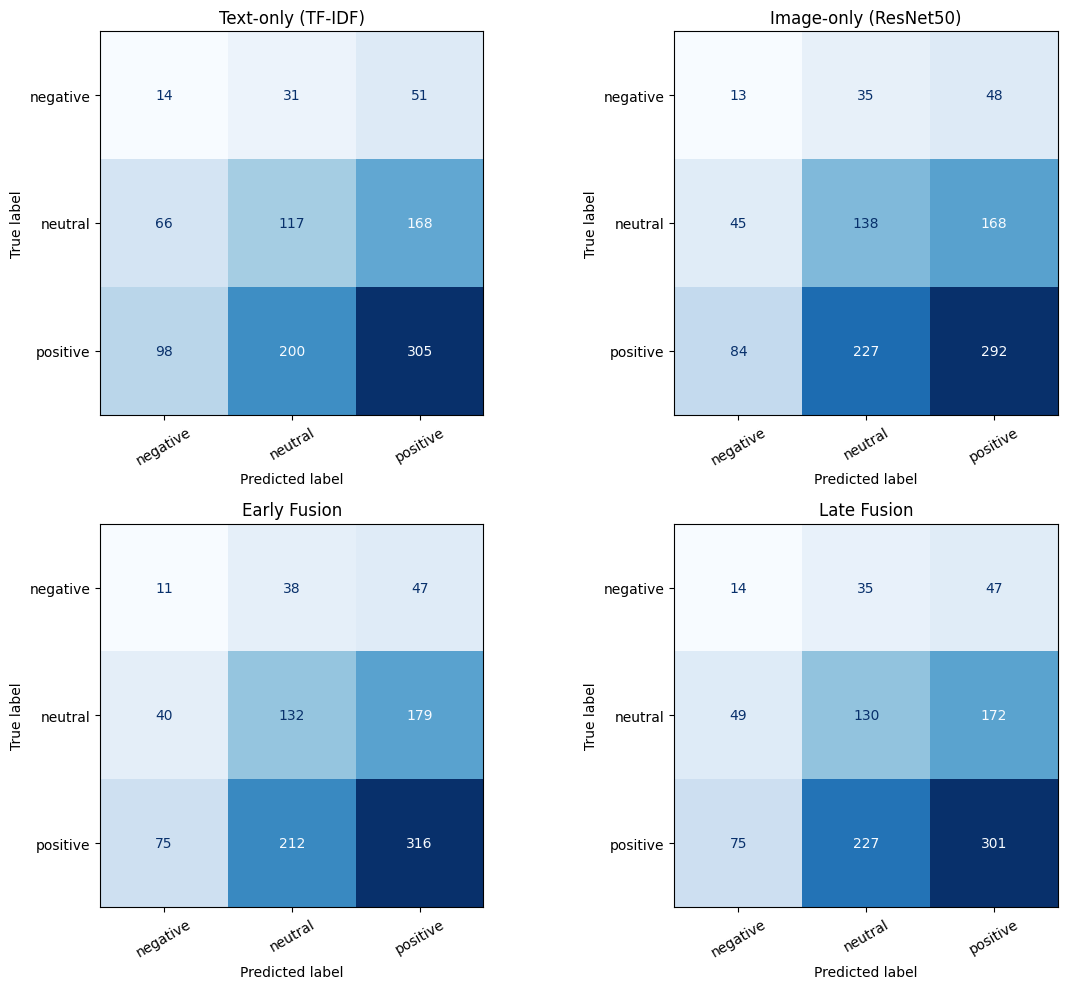


Final evaluation saved successfully!


In [24]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

y_test = test_df["sentiment_3class"]

# Predictions from each model
pred_text = text_model.predict(X_test_text)
pred_image = image_model.predict(X_test_img)
pred_early = early_model.predict(X_test_fusion)

# Late fusion probabilities
text_test_probs = text_model.predict_proba(X_test_text)
image_test_probs = image_model.predict_proba(X_test_img)

assert np.array_equal(
    text_model.classes_,
    image_model.classes_
)

late_test_probs = (
    best_image_weight * image_test_probs
    + (1 - best_image_weight) * text_test_probs
)

pred_late = text_model.classes_[
    np.argmax(late_test_probs, axis=1)
]

# Models to evaluate
models = {
    "Text-only (TF-IDF)": (
        pred_text,
        text_test_probs,
        text_model.classes_
    ),
    "Image-only (ResNet50)": (
        pred_image,
        image_test_probs,
        image_model.classes_
    ),
    "Early Fusion": (
        pred_early,
        early_model.predict_proba(X_test_fusion),
        early_model.classes_
    ),
    "Late Fusion": (
        pred_late,
        late_test_probs,
        text_model.classes_
    )
}

results = []

for name, (pred, probs, classes) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(
            y_test, pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, pred, average="weighted"
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, pred
        ),
        "Macro ROC-AUC": roc_auc_score(
            y_test,
            probs,
            labels=classes,
            multi_class="ovr",
            average="macro"
        )
    })

test_results_df = pd.DataFrame(results)

display(test_results_df.round(4))

# Classification reports and confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, (pred, probs, classes)) in zip(
    axes.flat, models.items()
):

    print(f"\n{name}")
    print(
        classification_report(
            y_test,
            pred,
            labels=classes,
            zero_division=0
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=classes,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()

# Save results and figure
import os

output_folder = "/content/memotion_project"
os.makedirs(output_folder, exist_ok=True)

test_results_df.to_csv(
    os.path.join(output_folder, "test_results.csv"),
    index=False
)

plt.savefig(
    os.path.join(output_folder, "confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFinal evaluation saved successfully!")

In [25]:
import os
import numpy as np

save_dir = "/content/memotion_project"
os.makedirs(save_dir, exist_ok=True)

np.savez_compressed(
    os.path.join(save_dir, "image_features.npz"),
    X_train_img=X_train_img,
    X_val_img=X_val_img,
    X_test_img=X_test_img
)

print("Image features saved successfully!")

Image features saved successfully!


In [26]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Use the best model: Early Fusion
y_pred = early_model.predict(X_test_fusion)

# Compare actual and predicted labels
error_df = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": y_pred
})

error_df["Correct"] = (
    error_df["Actual"] == error_df["Predicted"]
)

print("Total test samples:", len(error_df))
print("Correct predictions:", error_df["Correct"].sum())
print("Incorrect predictions:", (~error_df["Correct"]).sum())

print("\nMost common classification mistakes:")
display(
    error_df.loc[~error_df["Correct"]]
    .groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

Total test samples: 1050
Correct predictions: 459
Incorrect predictions: 591

Most common classification mistakes:


,Actual,Predicted,Count
5,positive,neutral,212
3,neutral,positive,179
4,positive,negative,75
1,negative,positive,47
2,neutral,negative,40
0,negative,neutral,38


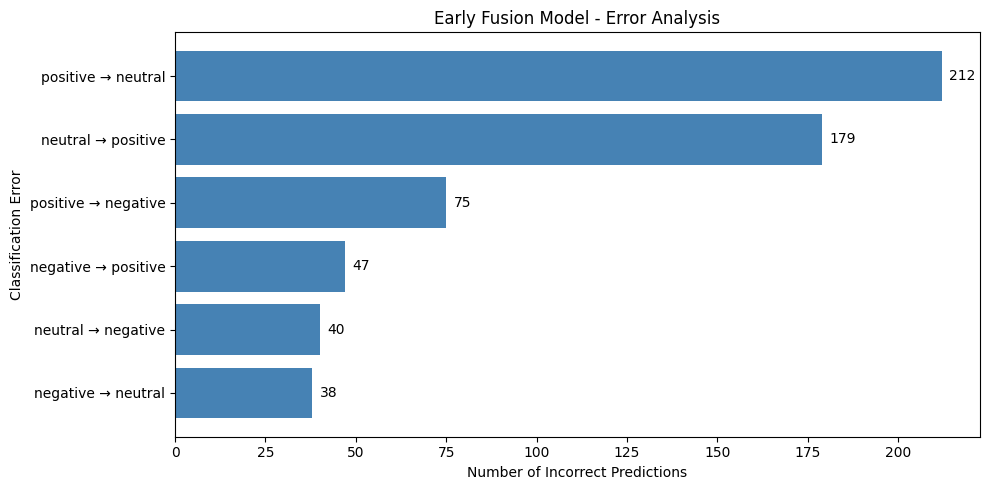

Error analysis chart saved successfully!


In [27]:
import matplotlib.pyplot as plt

errors = (
    error_df[~error_df["Correct"]]
    .groupby(["Actual", "Predicted"])
    .size()
    .sort_values(ascending=True)
)

labels = [
    f"{actual} → {predicted}"
    for actual, predicted in errors.index
]

plt.figure(figsize=(10, 5))

plt.barh(labels, errors.values, color="steelblue")

plt.xlabel("Number of Incorrect Predictions")
plt.ylabel("Classification Error")
plt.title("Early Fusion Model - Error Analysis")

for i, value in enumerate(errors.values):
    plt.text(value + 2, i, str(value), va="center")

plt.tight_layout()

plt.savefig(
    "/content/memotion_project/error_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Error analysis chart saved successfully!")

In [28]:
import pandas as pd

# Find incorrect predictions
wrong_indices = error_df.index[
    ~error_df["Correct"]
]

# Select 10 examples
sample_indices = wrong_indices[:10]

examples = test_df.iloc[sample_indices].copy()

examples["Actual"] = error_df.loc[
    sample_indices, "Actual"
].values

examples["Predicted"] = error_df.loc[
    sample_indices, "Predicted"
].values

# Display results
display(
    examples[
        ["image_name", "clean_text",
         "Actual", "Predicted"]
    ]
)

,image_name,clean_text,Actual,Predicted
5,image_6.jpg,"1998: ""Don't get in car with strangers"" 2008: ...",negative,positive
60,image_61.jpg,nobody: rats in the 14th century: I am inevita...,positive,neutral
64,image_65.jpg,David 4 @itsdxvid The real reason Marvel moved...,positive,negative
119,image_120.jpg,CHALLENGE ACCEPTED! Friend: You can't honestly...,positive,neutral
143,image_144.png,I WAS FOUR SEASONS ON A SHOW CALLED DOOGIE HOU...,neutral,positive
153,image_154.png,YOU'RE MY BEST FRIEND ALL RIGHT? YOU DON'T HA...,neutral,positive
174,image_175.jpg,STACEY B STARR YOU CANNOT BE SERIOUS,neutral,positive
190,image_191.jpg,@SODORMEMEZ ROWAN ATKINSON IS THAT YOU?,neutral,negative
200,image_201.png,Happy Birthday! Rowan At... Oh Sorry. Mr. Bean!,positive,negative
287,image_288.jpg,DIFFERENT BRAINS EPISODE 94 EXPLORING DIFFEREN...,neutral,positive


In [29]:
import matplotlib.pyplot as plt
from PIL import Image
import os

print("Image path column available:",
      "image_path" in test_df.columns)

print("\nAvailable columns:")
print(test_df.columns.tolist())

Image path column available: True

Available columns:
['Unnamed: 0', 'image_name', 'text_ocr', 'text_corrected', 'humour', 'sarcasm', 'offensive', 'motivational', 'overall_sentiment', 'sentiment_3class', 'image_path', 'image_exists', 'clean_text', 'image_hash']


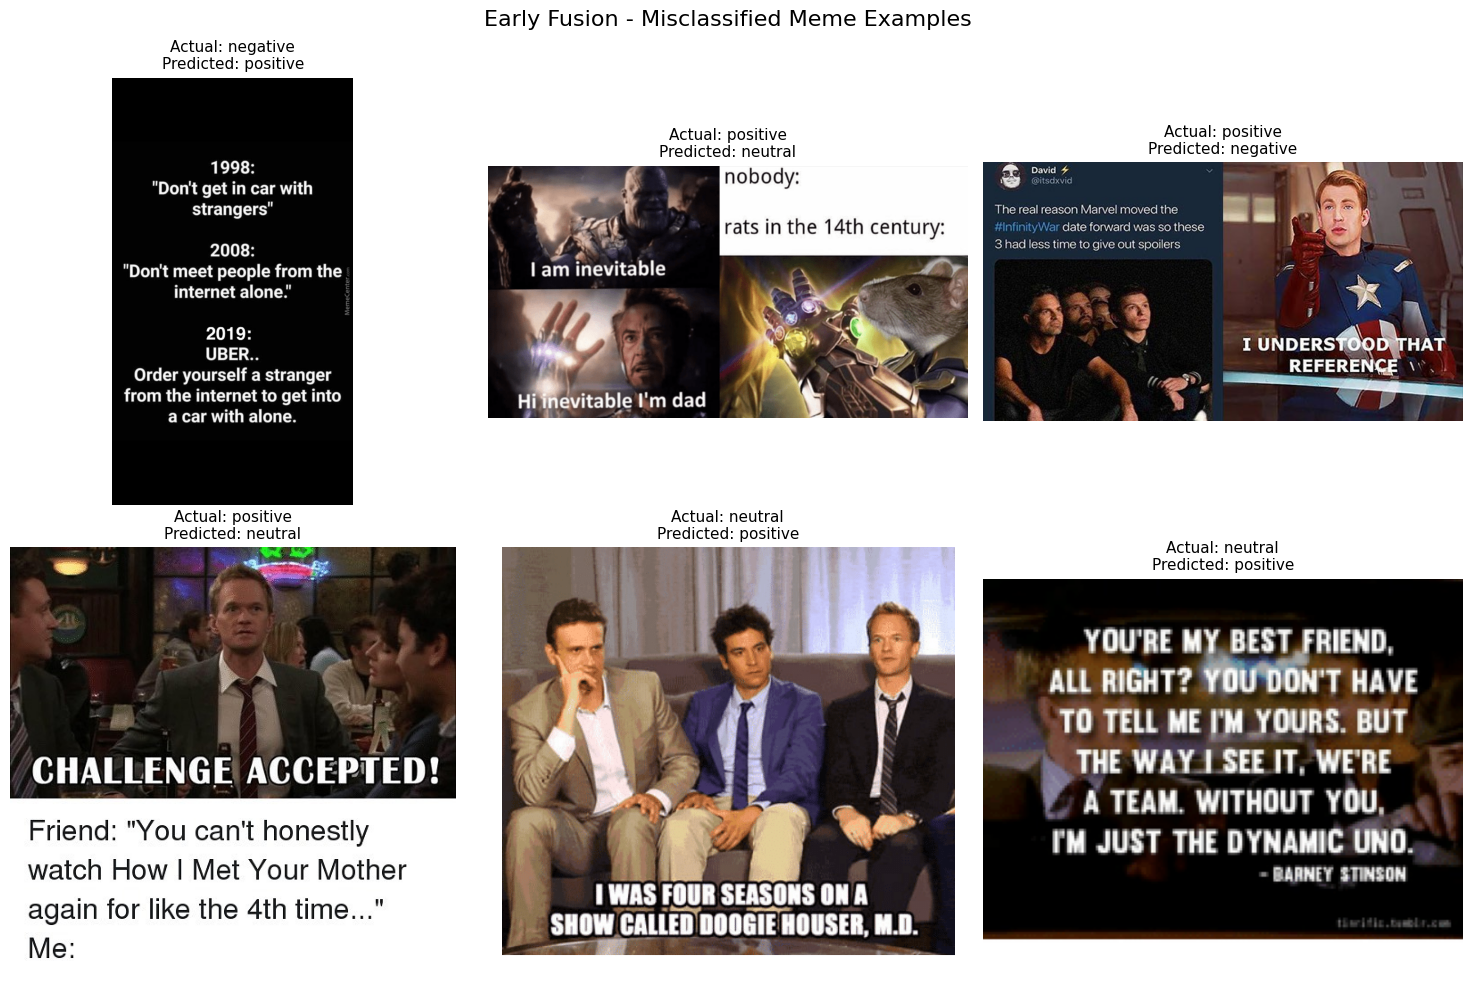

Misclassified meme examples saved successfully!


In [30]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import textwrap

# Select the first 6 incorrect predictions
wrong_indices = error_df.index[
    ~error_df["Correct"]
][:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, idx in zip(axes, wrong_indices):

    row = test_df.iloc[idx]
    actual = error_df.iloc[idx]["Actual"]
    predicted = error_df.iloc[idx]["Predicted"]

    image_path = row["image_path"]

    try:
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
    except Exception as e:
        ax.text(0.5, 0.5, "Image unavailable",
                ha="center", va="center")
        print(image_path, e)

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=11
    )
    ax.axis("off")

plt.suptitle(
    "Early Fusion - Misclassified Meme Examples",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "/content/memotion_project/misclassified_memes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Misclassified meme examples saved successfully!")

In [32]:

import joblib
import os

save_path = "/content/memotion_project"
os.makedirs(save_path, exist_ok=True)

joblib.dump(
    text_model,
    os.path.join(save_path, "text_only_model.joblib")
)

joblib.dump(
    tfidf_fusion,
    os.path.join(save_path, "text_vectorizer.joblib")
)

print("Text-only model and vectorizer saved successfully!")


Text-only model and vectorizer saved successfully!


In [33]:

!zip -r /content/memotion_project.zip /content/memotion_project


updating: content/memotion_project/ (stored 0%)
updating: content/memotion_project/error_analysis.png (deflated 26%)
updating: content/memotion_project/image_features.npz (deflated 0%)
updating: content/memotion_project/validation_resnet_features.npy (deflated 43%)
updating: content/memotion_project/misclassified_memes.png (deflated 1%)
updating: content/memotion_project/early_fusion_model.joblib (deflated 37%)
updating: content/memotion_project/confusion_matrices.png (deflated 21%)
updating: content/memotion_project/test_results.csv (deflated 40%)
updating: content/memotion_project/late_fusion_model.joblib (deflated 37%)
updating: content/memotion_project/test_resnet_features.npy (deflated 43%)
updating: content/memotion_project/validation.csv (deflated 77%)
updating: content/memotion_project/image_only_model.joblib (deflated 5%)
updating: content/memotion_project/train.csv (deflated 78%)
updating: content/memotion_project/train_resnet_features.npy (deflated 43%)
updating: content/mem